# Analyse métier - Étoile Ventes

**Table Druid :** fact_order_item  
**Grain :** Une ligne par article de commande (ordre x ligne)

Ce notebook exécute cinquante visuels depuis la table Druid dénormalisée indiquée ci-dessus. La première cellule détecte une connexion accessible depuis le noyau Python : `http://127.0.0.1:25019/druid/v2/sql` sur l’hôte ou `http://druid-router:8888/druid/v2/sql` dans Docker. Pour imposer une URL, définir `DRUID_SQL_URL_OVERRIDE` ou la variable d’environnement `DRUID_SQL_URL`.

**Limite du modèle :** Le GMV est le prix des articles hors fret et ne représente ni la marge ni le chiffre d’affaires net. Les montants sont additifs au grain article, mais un COUNT DISTINCT de commandes ne s’additionne pas entre catégories qui se recouvrent.

**Source du modèle :** [20_build_ebrasil_warehouse.py](https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py), blob GitHub `8b553b3970eb8f3f5804ac0072569cfade518c57`. Le script produit les six tables dénormalisées ; `docker/ebrasil-druid/ingest.py` les ingère sous les mêmes noms, sans rollup. Au démarrage, le notebook contrôle les six tables et les colonnes utilisées par ses graphiques via `INFORMATION_SCHEMA.COLUMNS`, ainsi que la présence de lignes dans sa table. Aucune donnée de démonstration ni dimension séparée n’est utilisée. La compatibilité du schéma est contrôlée ; la provenance des lignes dépend de l’initialisation eBrasil du dépôt.


In [1]:
import os
import socket
import warnings
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# None : sélection automatique depuis le noyau Python, indépendamment du navigateur.
# Pour imposer une adresse, renseigner ceci ou la variable d'environnement DRUID_SQL_URL.
DRUID_SQL_URL_OVERRIDE = None
HOST_SQL_URL = "http://127.0.0.1:25019/druid/v2/sql"
DOCKER_SQL_URL = "http://druid-router:8888/druid/v2/sql"
TABLE = "fact_order_item"
MODEL_TABLES = ["fact_logistics","fact_order","fact_order_item","fact_payment","fact_review","mart_customer_rfm"]
REQUIRED_COLUMNS = ["category_name","customer_city","customer_latitude","customer_longitude","customer_state","customer_zip_code","freight_value","gmv","item_count","line_total","order_id","price","product_description_length","product_id","product_photos_qty","product_weight_g","purchase_date_calendar_date","purchase_date_is_weekend","purchase_date_iso_week","purchase_date_quarter","purchase_date_weekday","purchase_date_year","purchase_time_day_part","purchase_time_hour","seller_city","seller_id","seller_state"]
MODEL_SOURCE = "https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py"
MODEL_SOURCE_BLOB_SHA = "8b553b3970eb8f3f5804ac0072569cfade518c57"

def normalize_sql_url(value):
    parsed = urlsplit(value.strip())
    if parsed.scheme not in ("http", "https") or not parsed.hostname:
        raise ValueError("DRUID_SQL_URL doit être une URL HTTP complète, sans syntaxe Markdown.")
    if parsed.username or parsed.password or parsed.query or parsed.fragment:
        raise ValueError("Ne pas inclure d'identifiants, de paramètres ou de fragment dans DRUID_SQL_URL.")
    netloc = parsed.netloc
    if parsed.hostname == "druid-router" and parsed.port == 25019:
        warnings.warn("Port corrigé : druid-router utilise 8888 ; 25019 est le port de l'hôte.")
        netloc = "druid-router:8888"
    if parsed.hostname in ("localhost", "127.0.0.1") and parsed.port == 8888:
        warnings.warn("Port hôte corrigé selon le dépôt : 127.0.0.1:25019.")
        netloc = "127.0.0.1:25019"
    path = parsed.path.rstrip("/") or "/druid/v2/sql"
    if path != "/druid/v2/sql":
        raise ValueError("Le point d'accès attendu est /druid/v2/sql.")
    return urlunsplit((parsed.scheme, netloc, path, "", ""))

def select_druid_url():
    explicit = DRUID_SQL_URL_OVERRIDE or os.getenv("DRUID_SQL_URL", "").strip()
    try:
        socket.getaddrinfo("druid-router", 8888)
        docker_dns = True
    except OSError:
        docker_dns = False
    in_docker = Path("/.dockerenv").exists() or docker_dns
    candidates = [DOCKER_SQL_URL, HOST_SQL_URL] if in_docker else [HOST_SQL_URL, DOCKER_SQL_URL]
    if explicit:
        candidates = [normalize_sql_url(explicit)]
    errors = []
    for url in candidates:
        try:
            response = requests.post(url, json={"query": "SELECT 1 AS connexion_ok", "resultFormat": "object"}, timeout=(3, 8))
            response.raise_for_status()
            result = response.json()
            if not isinstance(result, list) or not result or result[0].get("connexion_ok") != 1:
                raise ValueError("Ce service ne répond pas comme Druid SQL.")
            return url
        except (requests.RequestException, ValueError) as exc:
            errors.append(f"{url} : {exc}")
    raise ConnectionError(
        "Connexion Druid impossible depuis ce noyau Python.\nWindows : " + HOST_SQL_URL +
        "\nDocker du dépôt : " + DOCKER_SQL_URL +
        "\nVérifier druid-router et le réseau Docker. Corriger ou supprimer la variable DRUID_SQL_URL si elle est définie.\n" +
        "\n".join(errors)
    )

DRUID_SQL_URL = select_druid_url()

def druid_sql(sql):
    try:
        response = requests.post(DRUID_SQL_URL,
            json={"query": sql, "resultFormat": "object",
                  "context": {"sqlTimeZone": "UTC", "useApproximateCountDistinct": False}}, timeout=(5, 120))
    except requests.RequestException as exc:
        raise ConnectionError(f"Druid inaccessible à {DRUID_SQL_URL}. Relancer la cellule de connexion.") from exc
    if not response.ok:
        raise RuntimeError(f"Druid SQL HTTP {response.status_code}\nSQL : {sql}\n{response.text[:3000]}")
    data = response.json()
    if not isinstance(data, list):
        raise ValueError("Druid doit renvoyer une liste d'objets JSON.")
    return pd.DataFrame(data)

# Toutes les données analysées proviennent des tables dénormalisées exposées par Druid.
model_names = ", ".join("'" + name + "'" for name in MODEL_TABLES)
schema = druid_sql(
    'SELECT TABLE_NAME AS "table_name", COLUMN_NAME AS "column_name", DATA_TYPE AS "data_type" '
    "FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'druid' AND TABLE_NAME IN (" + model_names + ")"
)
if schema.empty:
    raise RuntimeError("Aucune étoile eBrasil dans Druid : exécuter l'initialisation du dépôt.")
missing_tables = set(MODEL_TABLES) - set(schema["table_name"])
if missing_tables:
    raise RuntimeError("Tables Druid manquantes : " + ", ".join(sorted(missing_tables)))
present_columns = set(schema.loc[schema["table_name"] == TABLE, "column_name"])
missing_columns = set(REQUIRED_COLUMNS) - present_columns
if missing_columns:
    raise RuntimeError(f"Schéma incompatible pour {TABLE}. Colonnes dénormalisées manquantes : " +
        ", ".join(sorted(missing_columns)) + ". Reconstruire avec 20_build_ebrasil_warehouse.py puis réingérer dans Druid.")
row_count = int(druid_sql(f'SELECT COUNT(*) AS lignes FROM "{TABLE}"').iloc[0]["lignes"])
if row_count == 0:
    raise RuntimeError(f"La table Druid {TABLE} est vide.")
print("Druid SQL :", DRUID_SQL_URL)
print(f"Table : {TABLE} | {row_count:,} lignes | {len(REQUIRED_COLUMNS)} colonnes contrôlées")
print("Source du modèle :", MODEL_SOURCE)
display(schema.loc[schema["table_name"] == TABLE].reset_index(drop=True))


Druid SQL : http://127.0.0.1:25019/druid/v2/sql
Table : fact_order_item | 112,650 lignes | 27 colonnes contrôlées
Source du modèle : https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py


,table_name,column_name,data_type
0,fact_order_item,__time,TIMESTAMP
1,fact_order_item,order_id,VARCHAR
2,fact_order_item,order_item_id,VARCHAR
3,fact_order_item,purchase_timestamp,VARCHAR
4,fact_order_item,purchase_date_key,VARCHAR
5,fact_order_item,purchase_time_key,VARCHAR
6,fact_order_item,customer_unique_id,VARCHAR
7,fact_order_item,product_id,VARCHAR
8,fact_order_item,category_name,VARCHAR
9,fact_order_item,seller_id,VARCHAR


In [2]:
def build_chart_sql(spec):
    """Construit une requête Druid avec des alias délimités, y compris VALUE."""
    dim, metric, kind = spec["dim"], spec["metric"], spec["kind"]
    fields = [dim["sql"] + ' AS "x"']
    if dim.get("series"):
        fields.append(dim["series"] + ' AS "series"')
    fields.append(metric["sql"] + ' AS "value"')
    group_by = "1, 2" if dim.get("series") else "1"
    order_by = '"x"' if kind == "line" else '"value" DESC'
    table_name = TABLE.replace('"', '""')
    return ('SELECT ' + ', '.join(fields) + ' FROM "' + table_name +
            '" GROUP BY ' + group_by + ' ORDER BY ' + order_by + ' LIMIT 40')

def run_chart(spec):
    dim,metric,kind=spec["dim"],spec["metric"],spec["kind"]
    if dim["type"]=="client":
        xcol=dim["sql"].replace('"',""); frame=rfm.copy(); scol=(dim.get("series") or "").replace('"',"")
        if xcol not in frame.columns: raise KeyError("Dimension RFM manquante: "+xcol)
        by=[xcol]+([scol] if scol else [])
        if metric["pandas"]=="customer_unique_id": grouped=frame.groupby(by,dropna=False)["customer_unique_id"].nunique().reset_index(name="value")
        else:
            agg="sum" if metric["pandas"]=="monetary" else "mean"
            grouped=frame.groupby(by,dropna=False)[metric["pandas"]].agg(agg).reset_index(name="value")
        if scol: grouped=grouped.pivot(index=xcol,columns=scol,values="value").fillna(0).head(25)
        else: grouped=grouped.sort_values("value",ascending=False).head(25).set_index(xcol)["value"]
    else:
        sql = build_chart_sql(spec)
        result=druid_sql(sql)
        if result.empty: print("Aucune donnée pour",spec["title"]); return
        if dim.get("series"): grouped=result.pivot_table(index="x",columns="series",values="value",aggfunc="sum",fill_value=0).head(25)
        else:
            result=result.sort_values("x" if kind=="line" else "value",ascending=(kind=="line")); grouped=result.set_index("x")["value"].head(40)
    fig,ax=plt.subplots(figsize=(10,5))
    if isinstance(grouped,pd.DataFrame):
        if kind=="heatmap":
            img=ax.imshow(grouped.values,aspect="auto",cmap="YlGnBu")
            ax.set_yticks(range(len(grouped.index))); ax.set_yticklabels([str(v) for v in grouped.index])
            ax.set_xticks(range(len(grouped.columns))); ax.set_xticklabels([str(v) for v in grouped.columns],rotation=45,ha="right")
            fig.colorbar(img,ax=ax,label=metric["label"])
        else: grouped.plot(kind="bar",stacked=True,ax=ax,colormap="tab20"); ax.legend(title="Série",bbox_to_anchor=(1.02,1),loc="upper left")
    elif kind=="line": grouped.plot(kind="line",marker="o",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    elif kind=="scatter": ax.scatter(pd.to_numeric(pd.Series(grouped.index),errors="coerce"),grouped.values,color="#148A8A",alpha=.75)
    else: grouped.plot(kind="bar",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    ax.set_title(spec["title"]); ax.set_xlabel(dim["label"]); ax.set_ylabel(metric["label"])
    fig.tight_layout(); plt.show(); plt.close(fig)


## 1. Évolution des ventes et saisonnalité

Suivre la valeur des articles et le volume vendu dans le temps pour distinguer tendance, saisonnalité et ruptures.

**Drill-down :** Date d’achat : année > trimestre > mois > jour; puis partie du jour > heure.

Visuel 1 - Évolution des ventes et saisonnalité - Mois d’achat


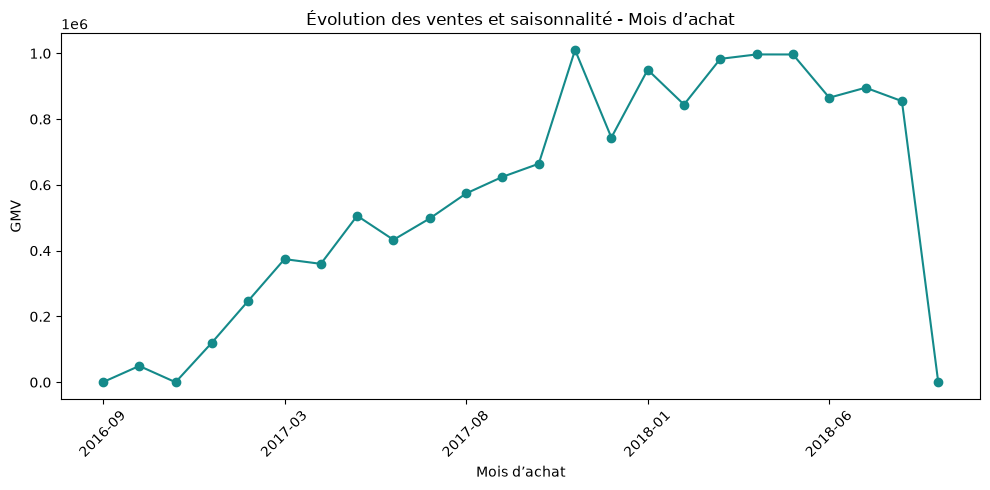

Visuel 2 - Évolution des ventes et saisonnalité - Année


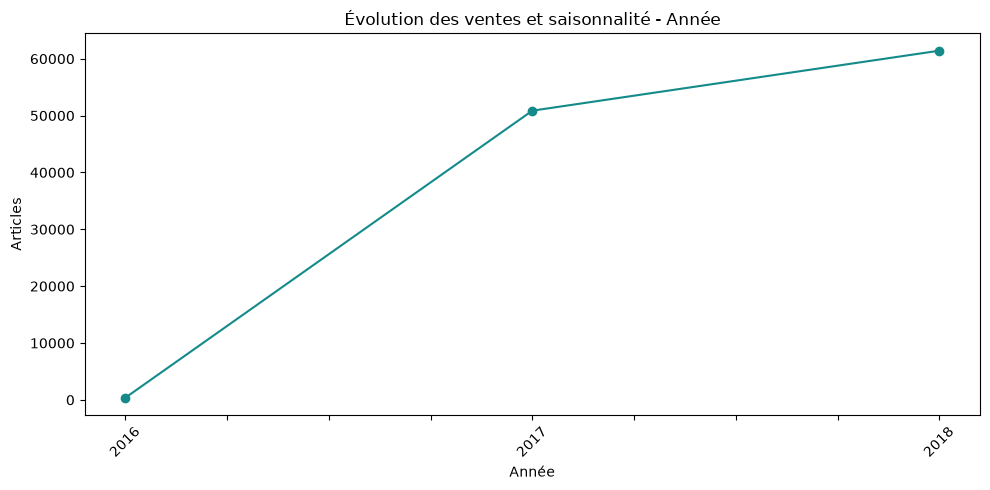

Visuel 3 - Évolution des ventes et saisonnalité - Trimestre


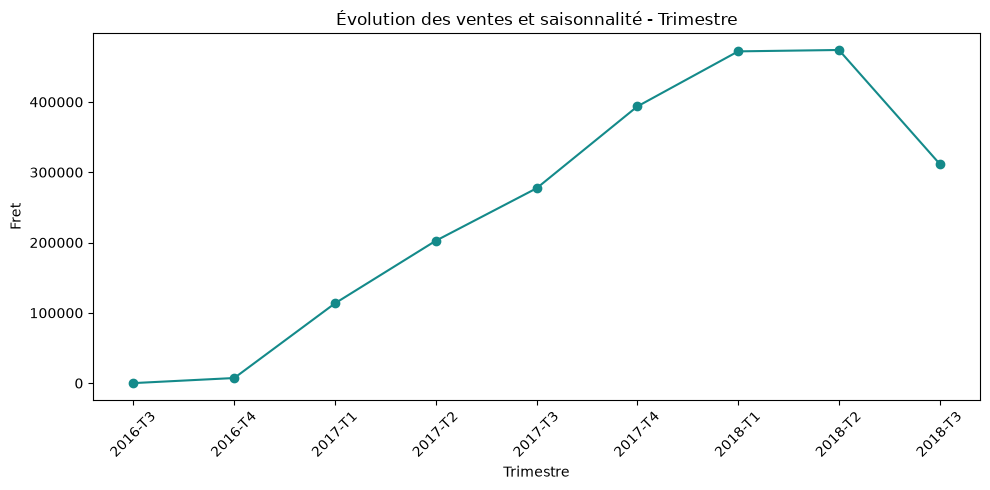

Visuel 4 - Évolution des ventes et saisonnalité - Semaine ISO


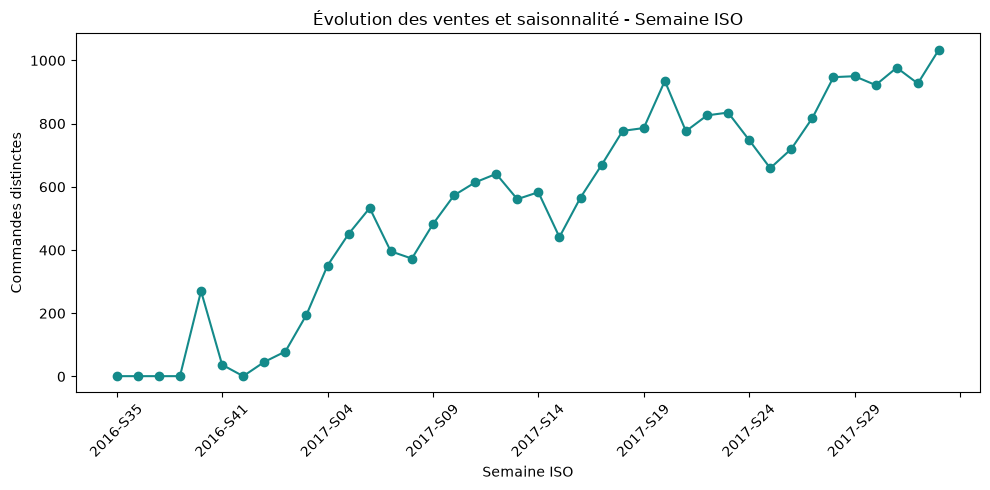

Visuel 5 - Évolution des ventes et saisonnalité - Jour de semaine


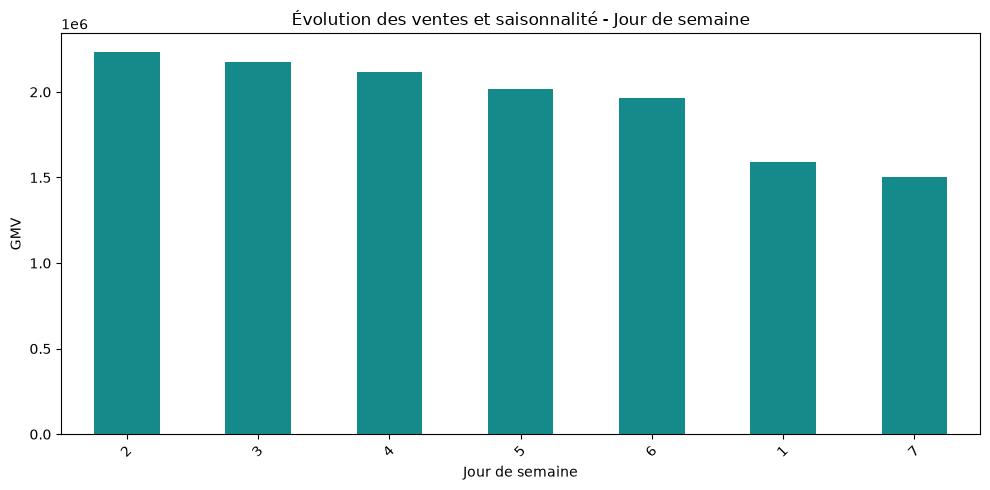

Visuel 6 - Évolution des ventes et saisonnalité - Partie du jour


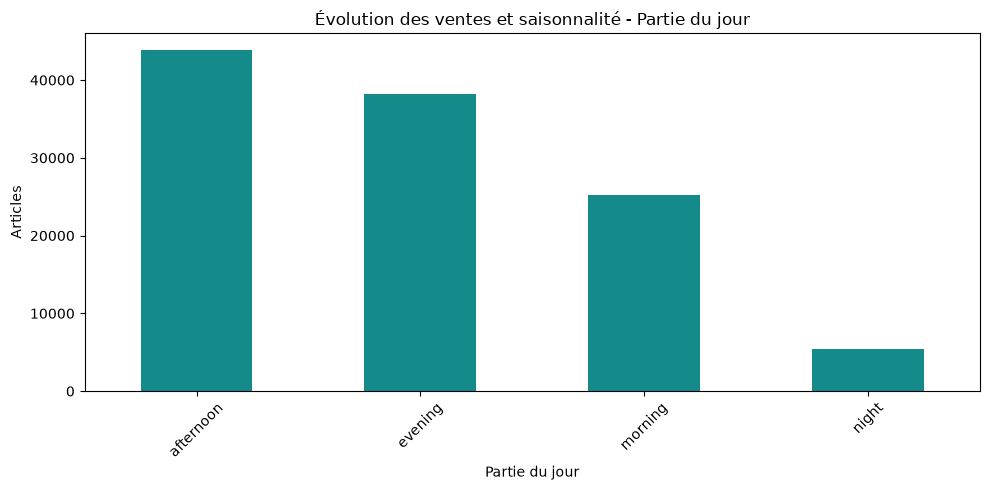

Visuel 7 - Évolution des ventes et saisonnalité - Heure


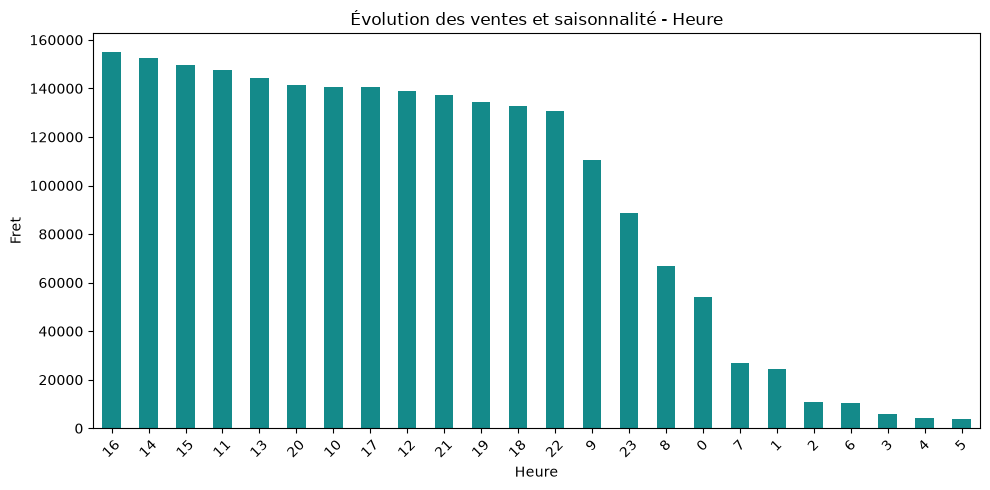

Visuel 8 - Évolution des ventes et saisonnalité - Jour ouvré / week-end


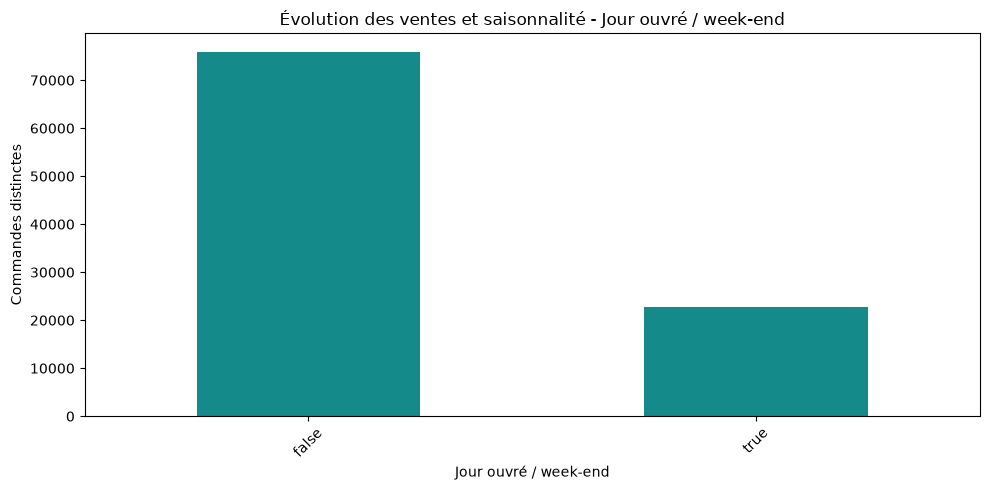

Visuel 9 - Évolution des ventes et saisonnalité - État client


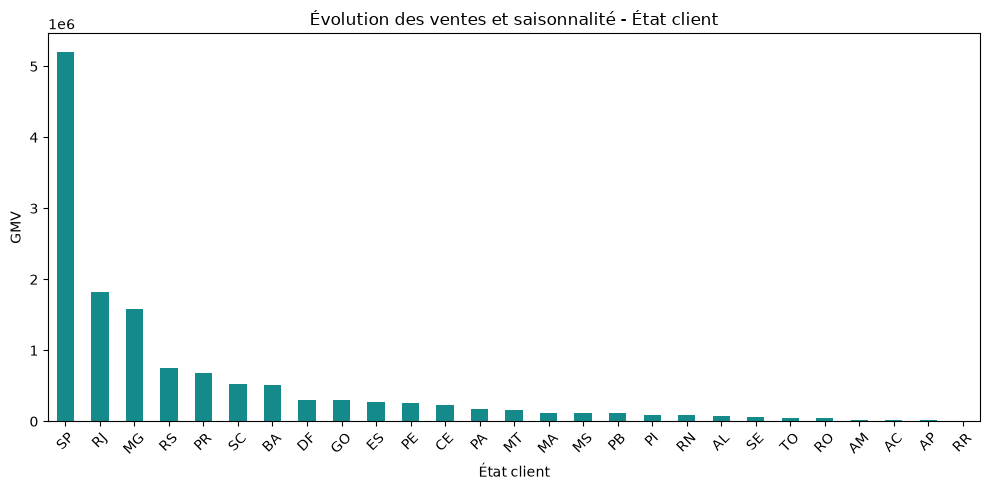

Visuel 10 - Évolution des ventes et saisonnalité - État vendeur


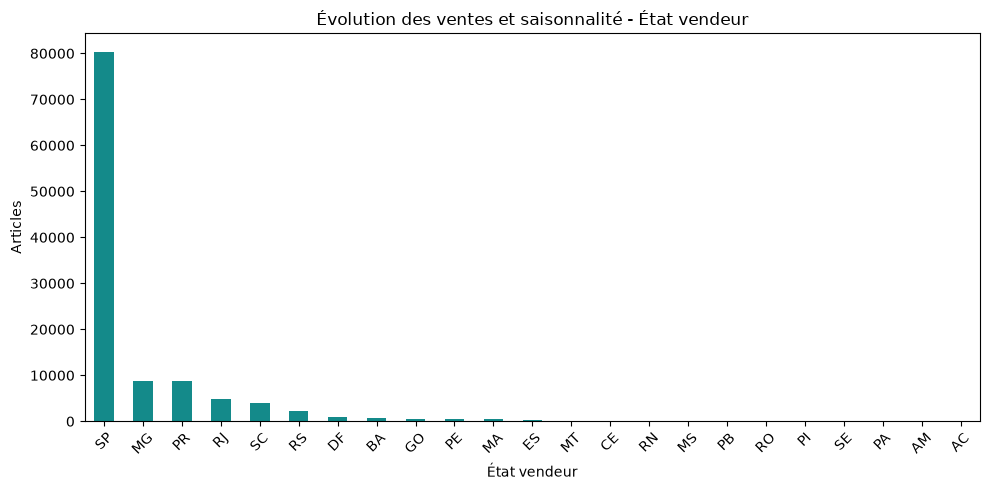

In [3]:
CHARTS=[
  {
    "n": 1,
    "title": "Évolution des ventes et saisonnalité - Mois d’achat",
    "dim": {
      "label": "Mois d’achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\", 1, 7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "line"
  },
  {
    "n": 2,
    "title": "Évolution des ventes et saisonnalité - Année",
    "dim": {
      "label": "Année",
      "sql": "\"purchase_date_year\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Évolution des ventes et saisonnalité - Trimestre",
    "dim": {
      "label": "Trimestre",
      "sql": "CONCAT(CAST(\"purchase_date_year\" AS VARCHAR), '-T', CAST(\"purchase_date_quarter\" AS VARCHAR))",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Fret",
      "sql": "SUM(\"freight_value\")",
      "pandas": "freight_value"
    },
    "kind": "line"
  },
  {
    "n": 4,
    "title": "Évolution des ventes et saisonnalité - Semaine ISO",
    "dim": {
      "label": "Semaine ISO",
      "sql": "CONCAT(CAST(\"purchase_date_year\" AS VARCHAR), '-S', LPAD(CAST(\"purchase_date_iso_week\" AS VARCHAR),2,'0'))",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "line"
  },
  {
    "n": 5,
    "title": "Évolution des ventes et saisonnalité - Jour de semaine",
    "dim": {
      "label": "Jour de semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Évolution des ventes et saisonnalité - Partie du jour",
    "dim": {
      "label": "Partie du jour",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Évolution des ventes et saisonnalité - Heure",
    "dim": {
      "label": "Heure",
      "sql": "\"purchase_time_hour\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Fret",
      "sql": "SUM(\"freight_value\")",
      "pandas": "freight_value"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Évolution des ventes et saisonnalité - Jour ouvré / week-end",
    "dim": {
      "label": "Jour ouvré / week-end",
      "sql": "\"purchase_date_is_weekend\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 9,
    "title": "Évolution des ventes et saisonnalité - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "bar"
  },
  {
    "n": 10,
    "title": "Évolution des ventes et saisonnalité - État vendeur",
    "dim": {
      "label": "État vendeur",
      "sql": "\"seller_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 2. Performance du portefeuille produit

Comparer les catégories et produits selon leur contribution à la valeur, au volume et au fret, en respectant la granularité article.

**Drill-down :** Catégorie > produit; produit > attributs physiques (poids, dimensions, photos).

Visuel 1 - Performance du portefeuille produit - Catégorie


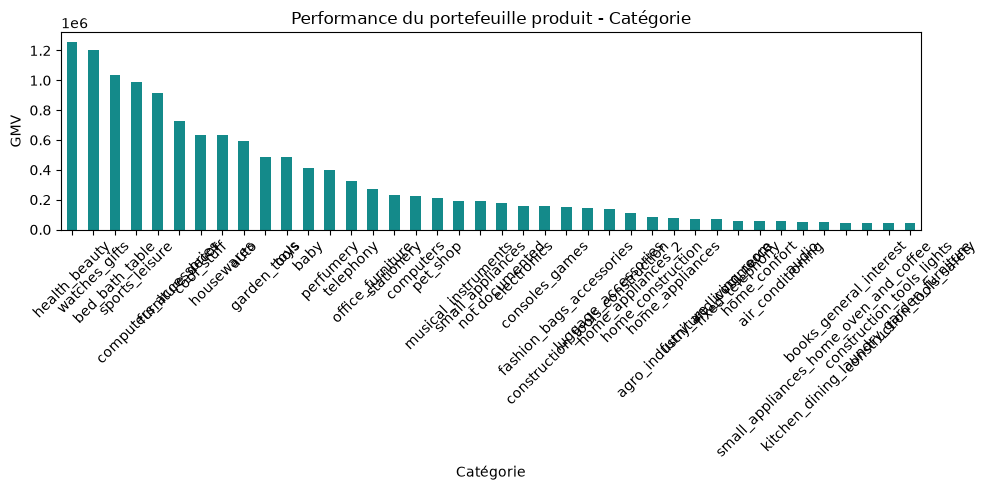

Visuel 2 - Performance du portefeuille produit - Produit


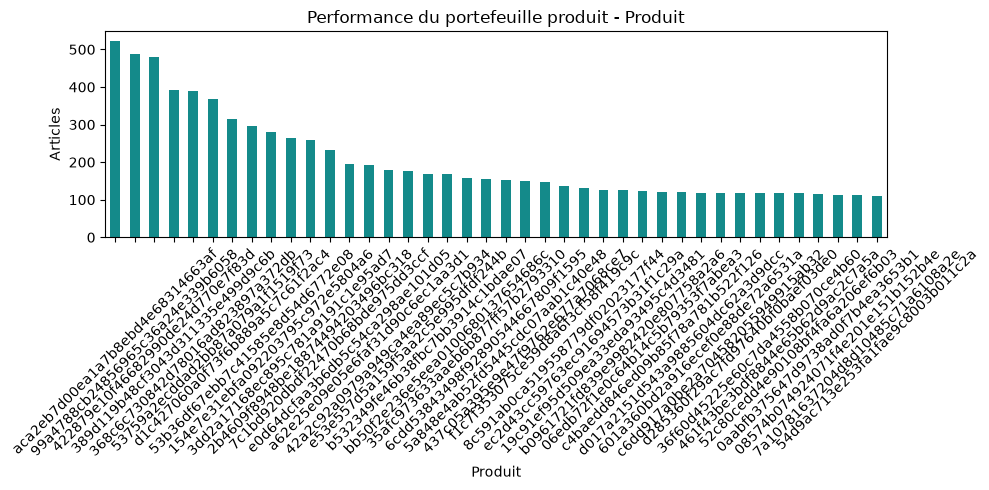

Visuel 3 - Performance du portefeuille produit - État vendeur


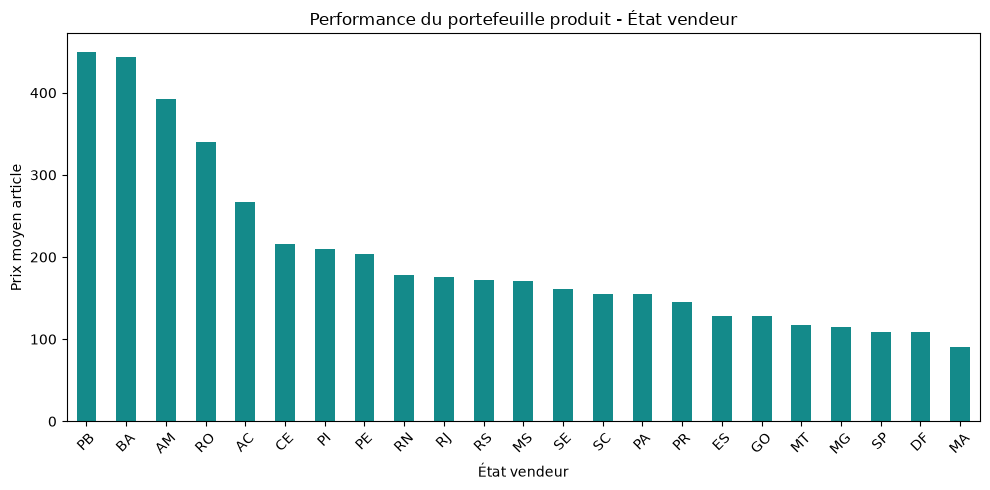

Visuel 4 - Performance du portefeuille produit - Ville vendeur


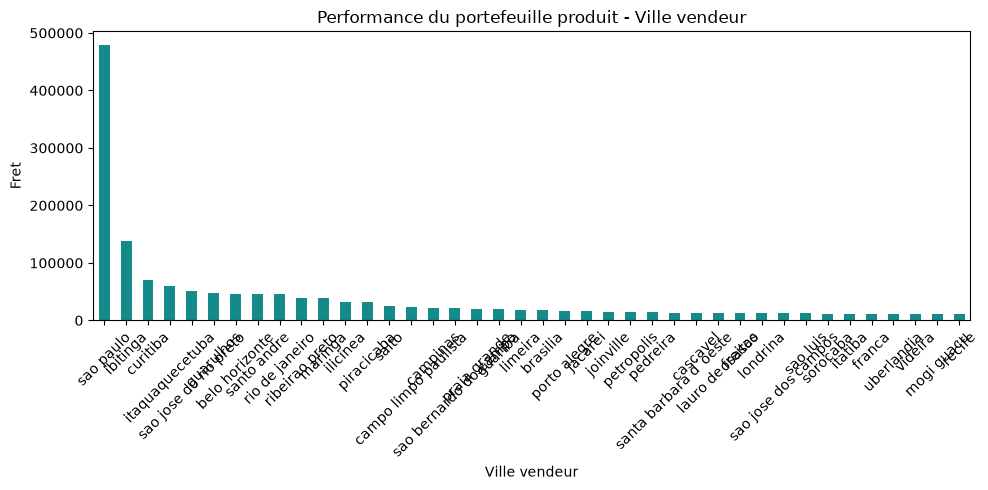

Visuel 5 - Performance du portefeuille produit - Poids produit par tranche


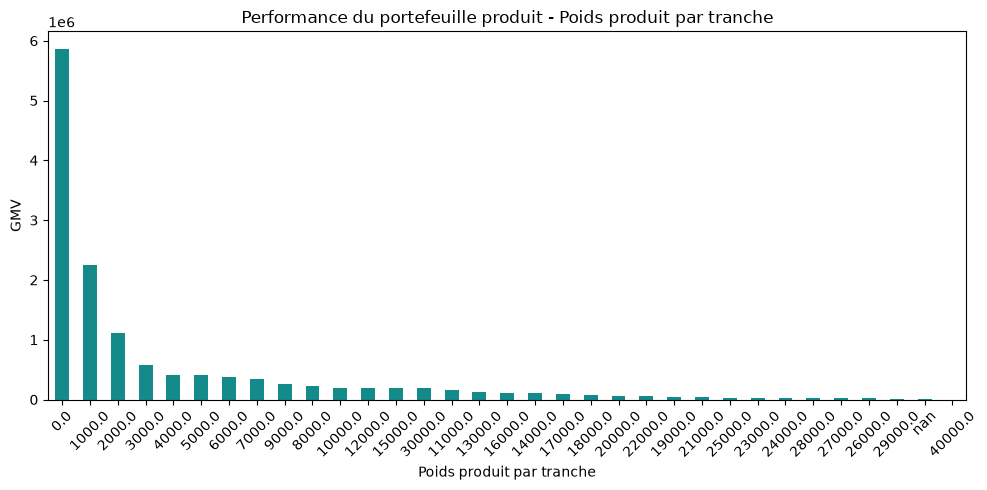

Visuel 6 - Performance du portefeuille produit - Photos produit


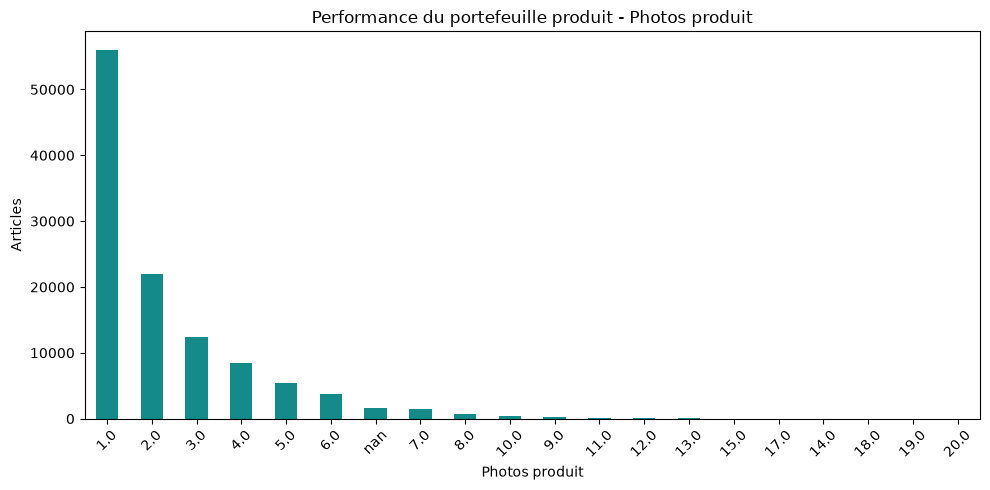

Visuel 7 - Performance du portefeuille produit - Longueur de description


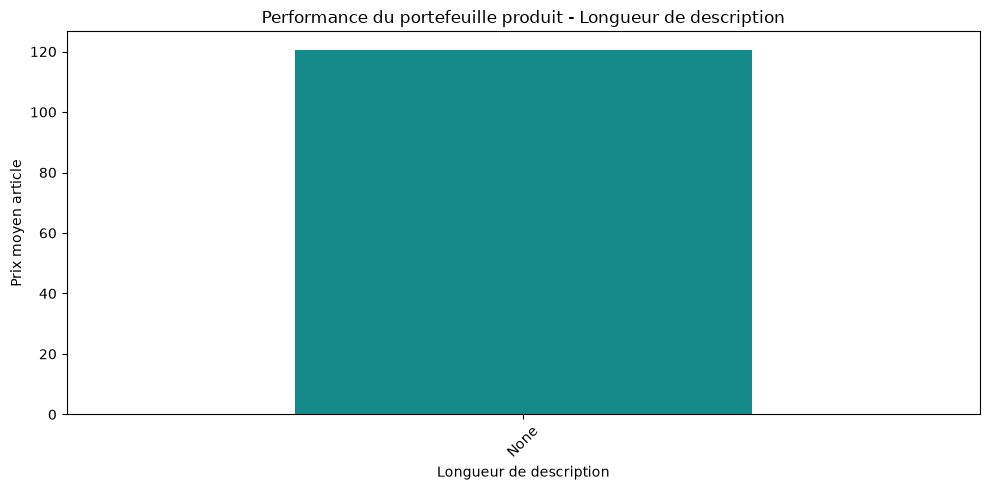

Visuel 8 - Performance du portefeuille produit - Mois d’achat


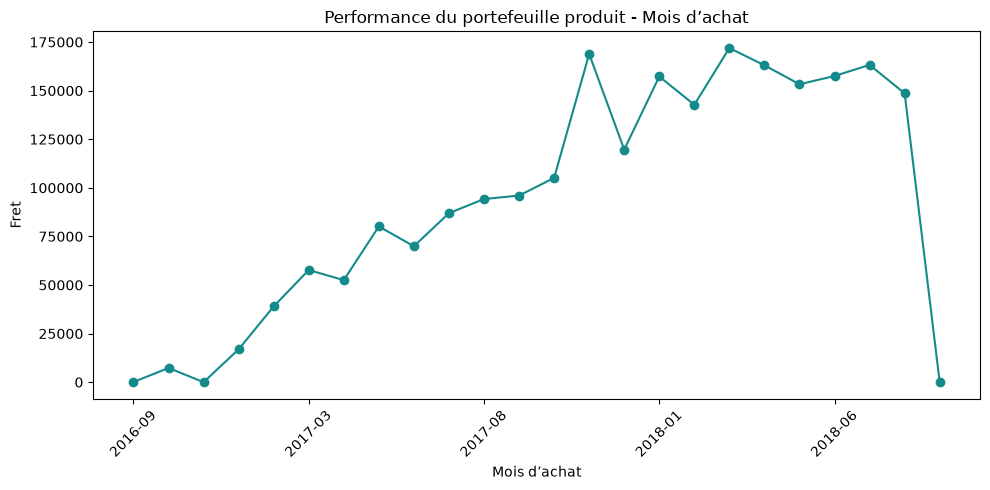

Visuel 9 - Performance du portefeuille produit - Catégorie x état vendeur


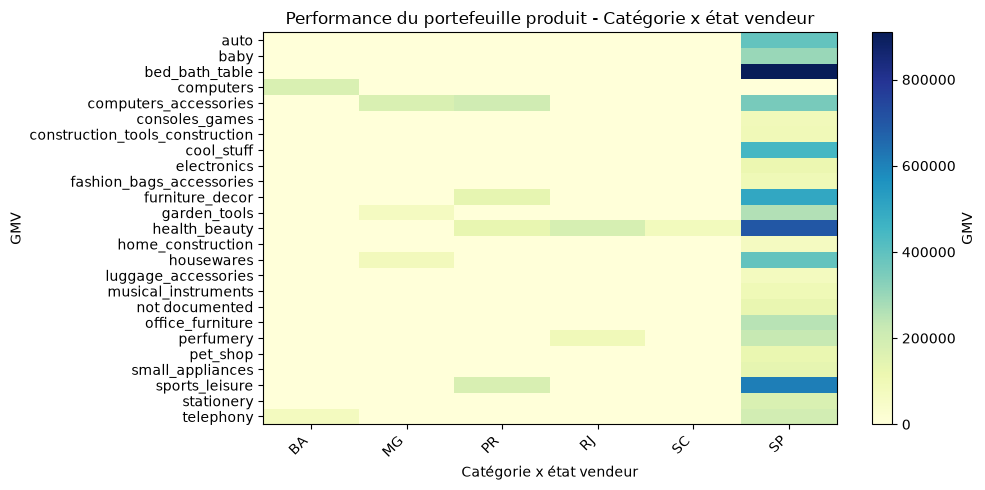

Visuel 10 - Performance du portefeuille produit - Catégorie x mois


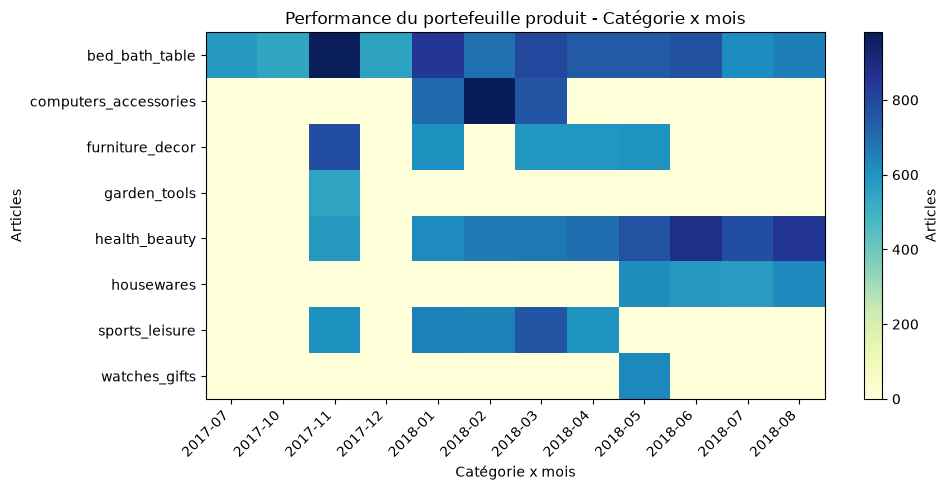

In [4]:
CHARTS=[
  {
    "n": 1,
    "title": "Performance du portefeuille produit - Catégorie",
    "dim": {
      "label": "Catégorie",
      "sql": "\"category_name\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Performance du portefeuille produit - Produit",
    "dim": {
      "label": "Produit",
      "sql": "\"product_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Performance du portefeuille produit - État vendeur",
    "dim": {
      "label": "État vendeur",
      "sql": "\"seller_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Prix moyen article",
      "sql": "AVG(\"price\")",
      "pandas": "price"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Performance du portefeuille produit - Ville vendeur",
    "dim": {
      "label": "Ville vendeur",
      "sql": "\"seller_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Fret",
      "sql": "SUM(\"freight_value\")",
      "pandas": "freight_value"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Performance du portefeuille produit - Poids produit par tranche",
    "dim": {
      "label": "Poids produit par tranche",
      "sql": "FLOOR(\"product_weight_g\" / 1000) * 1000",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Performance du portefeuille produit - Photos produit",
    "dim": {
      "label": "Photos produit",
      "sql": "\"product_photos_qty\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Performance du portefeuille produit - Longueur de description",
    "dim": {
      "label": "Longueur de description",
      "sql": "FLOOR(\"product_description_length\" / 100) * 100",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Prix moyen article",
      "sql": "AVG(\"price\")",
      "pandas": "price"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Performance du portefeuille produit - Mois d’achat",
    "dim": {
      "label": "Mois d’achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\", 1, 7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Fret",
      "sql": "SUM(\"freight_value\")",
      "pandas": "freight_value"
    },
    "kind": "line"
  },
  {
    "n": 9,
    "title": "Performance du portefeuille produit - Catégorie x état vendeur",
    "dim": {
      "label": "Catégorie x état vendeur",
      "sql": "\"category_name\"",
      "type": "categorical",
      "series": "\"seller_state\""
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Performance du portefeuille produit - Catégorie x mois",
    "dim": {
      "label": "Catégorie x mois",
      "sql": "\"category_name\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\", 1, 7)"
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 3. Performance commerciale vendeurs et clients

Repérer les concentrations de ventes par vendeur et par bassin client, sans attribuer de marge ou de rentabilité absente du modèle.

**Drill-down :** État > ville > vendeur ou client; vendeur > catégorie; client > commandes (drill-through via order_id).

Visuel 1 - Performance commerciale vendeurs et clients - Vendeur


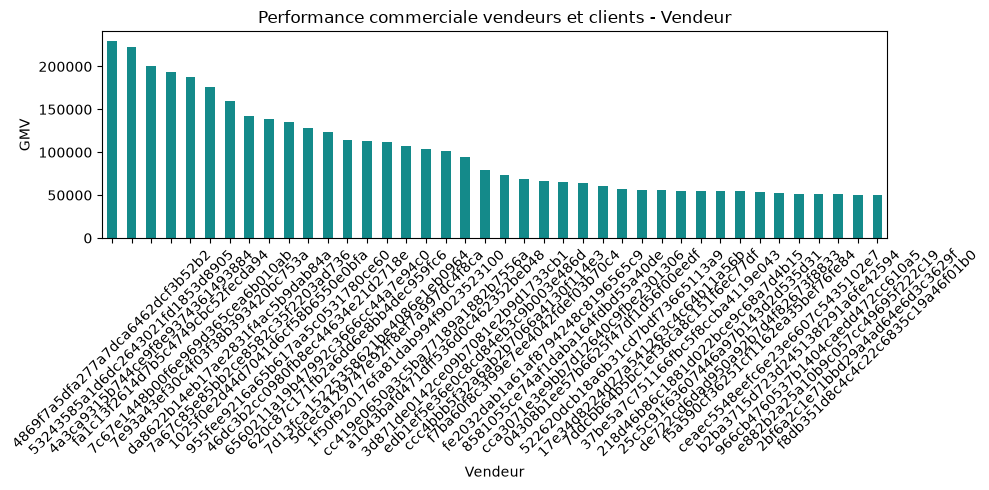

Visuel 2 - Performance commerciale vendeurs et clients - État vendeur


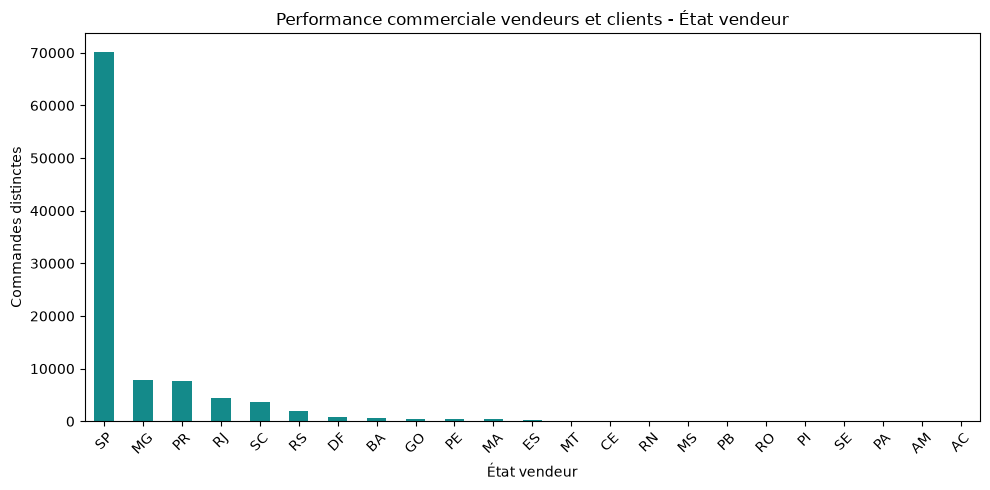

Visuel 3 - Performance commerciale vendeurs et clients - Ville vendeur


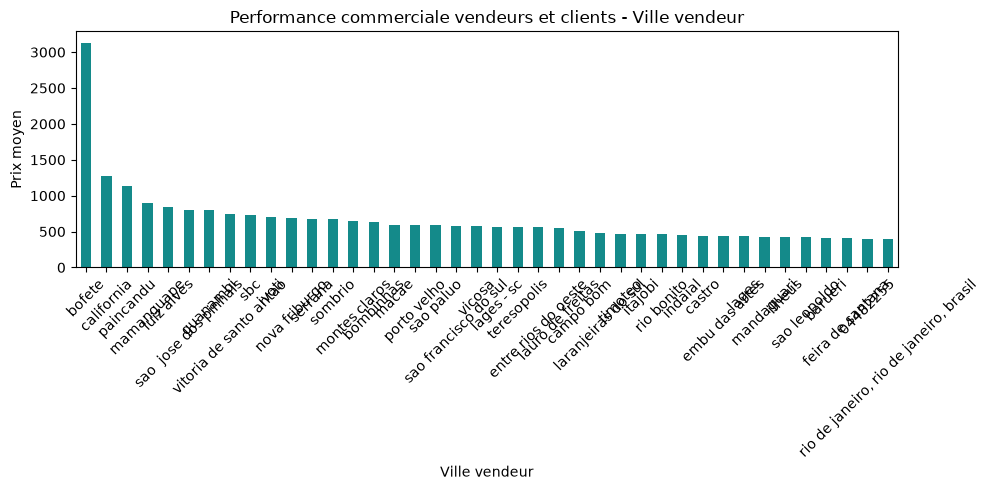

Visuel 4 - Performance commerciale vendeurs et clients - État client


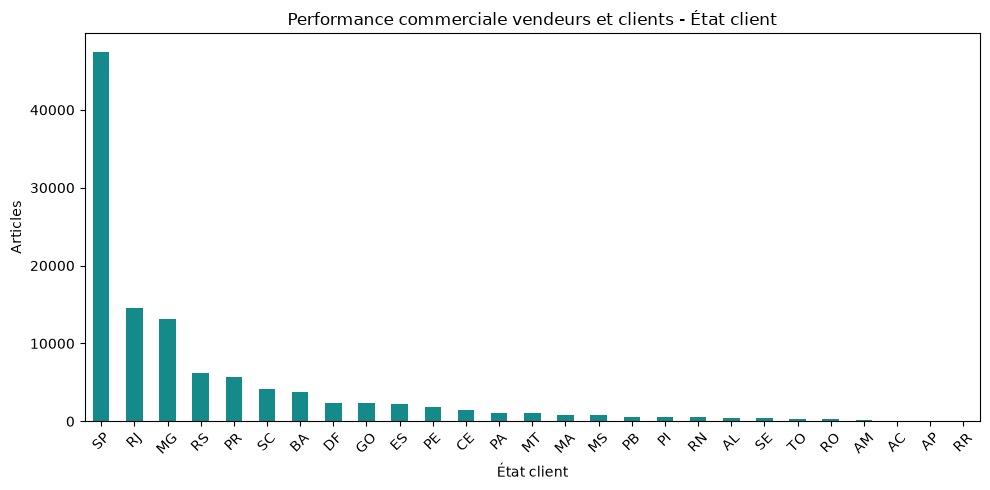

Visuel 5 - Performance commerciale vendeurs et clients - Ville client


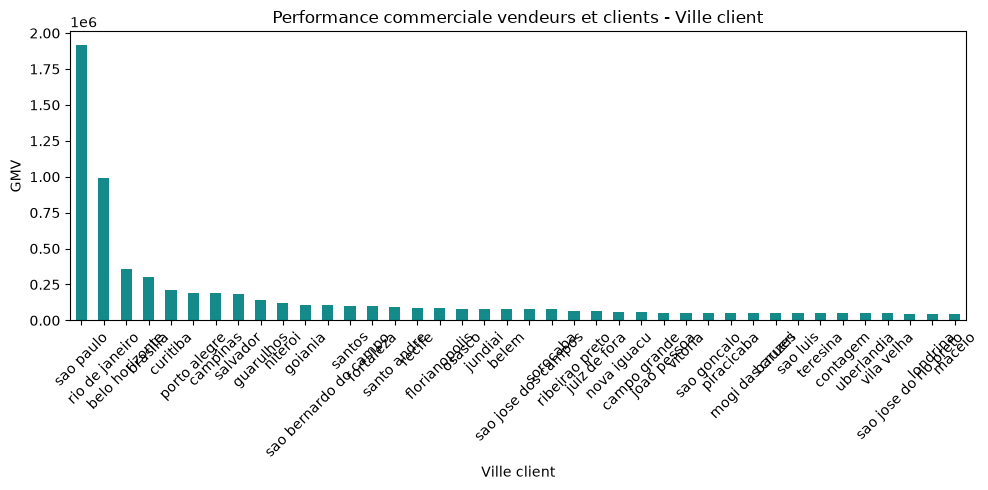

Visuel 6 - Performance commerciale vendeurs et clients - Code postal client


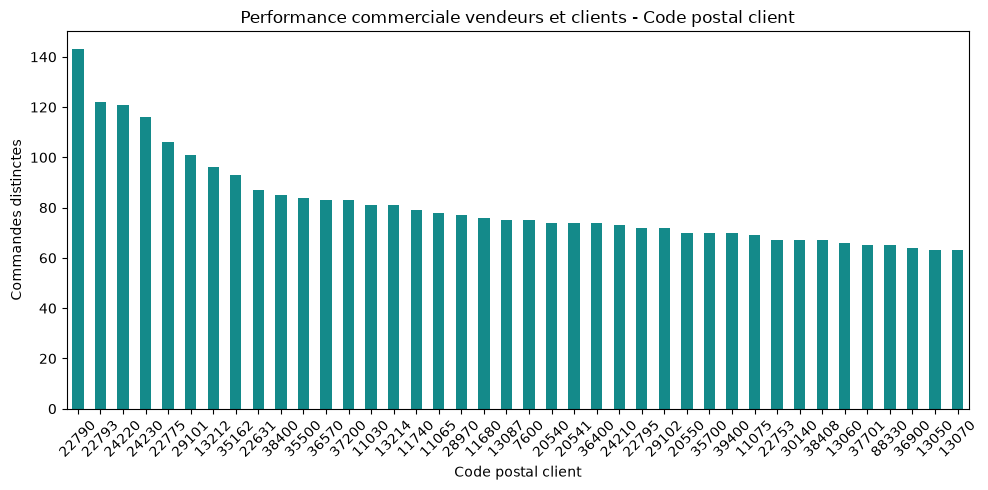

Visuel 7 - Performance commerciale vendeurs et clients - Catégorie


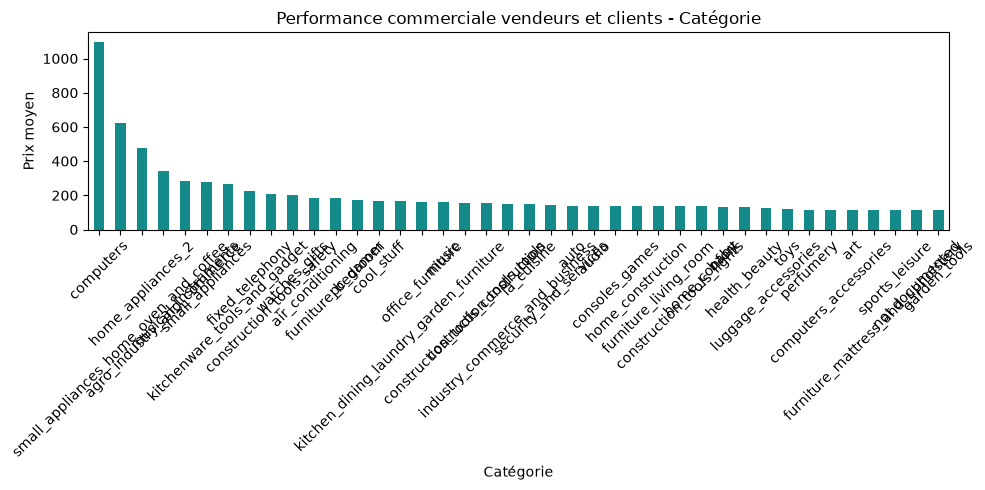

Visuel 8 - Performance commerciale vendeurs et clients - Mois d’achat


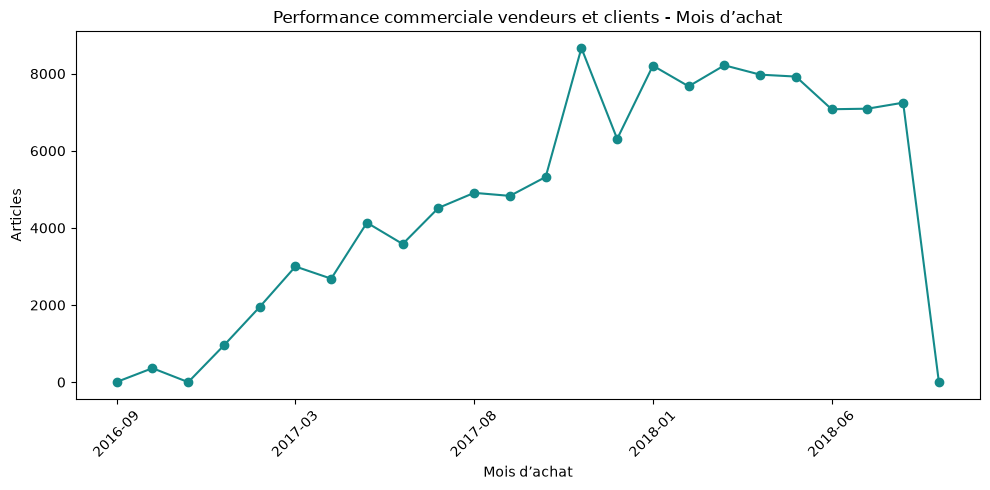

Visuel 9 - Performance commerciale vendeurs et clients - Vendeur x catégorie


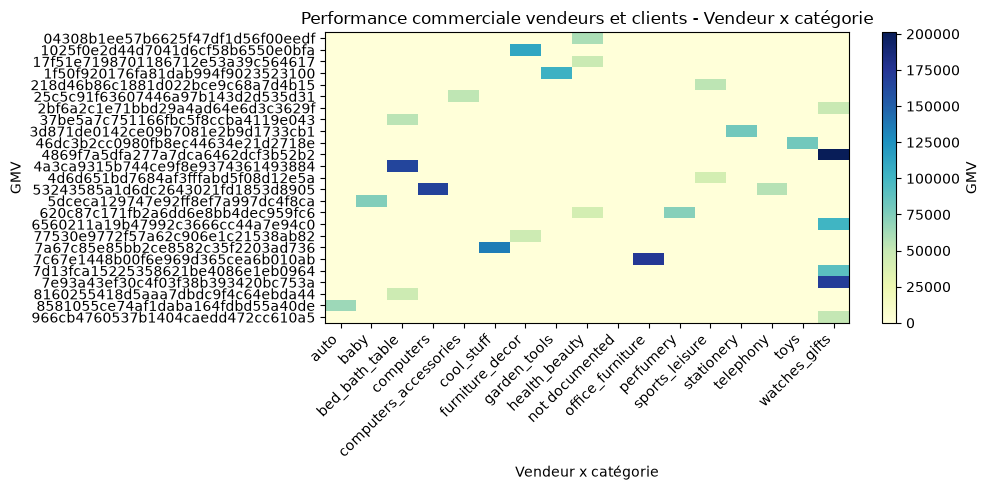

Visuel 10 - Performance commerciale vendeurs et clients - État vendeur x état client


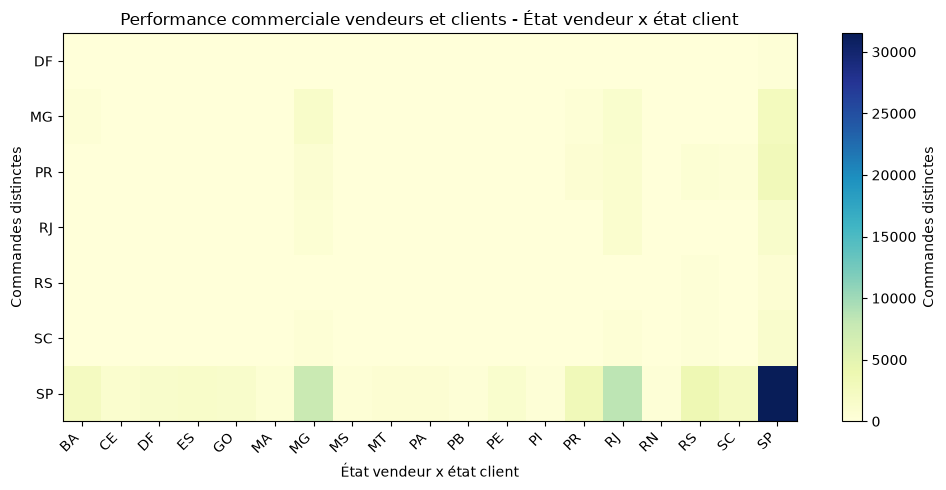

In [5]:
CHARTS=[
  {
    "n": 1,
    "title": "Performance commerciale vendeurs et clients - Vendeur",
    "dim": {
      "label": "Vendeur",
      "sql": "\"seller_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Performance commerciale vendeurs et clients - État vendeur",
    "dim": {
      "label": "État vendeur",
      "sql": "\"seller_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Performance commerciale vendeurs et clients - Ville vendeur",
    "dim": {
      "label": "Ville vendeur",
      "sql": "\"seller_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Prix moyen",
      "sql": "AVG(\"price\")",
      "pandas": "price"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Performance commerciale vendeurs et clients - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Performance commerciale vendeurs et clients - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Performance commerciale vendeurs et clients - Code postal client",
    "dim": {
      "label": "Code postal client",
      "sql": "\"customer_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Performance commerciale vendeurs et clients - Catégorie",
    "dim": {
      "label": "Catégorie",
      "sql": "\"category_name\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Prix moyen",
      "sql": "AVG(\"price\")",
      "pandas": "price"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Performance commerciale vendeurs et clients - Mois d’achat",
    "dim": {
      "label": "Mois d’achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\", 1, 7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "line"
  },
  {
    "n": 9,
    "title": "Performance commerciale vendeurs et clients - Vendeur x catégorie",
    "dim": {
      "label": "Vendeur x catégorie",
      "sql": "\"seller_id\"",
      "type": "categorical",
      "series": "\"category_name\""
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Performance commerciale vendeurs et clients - État vendeur x état client",
    "dim": {
      "label": "État vendeur x état client",
      "sql": "\"seller_state\"",
      "type": "categorical",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 4. Structure prix, fret et valeur de ligne

Distinguer valeur produit et coût de transport, analyser leur relation au niveau article et repérer des profils de lignes atypiques.

**Drill-down :** Catégorie > produit; prix et fret par tranches; comparaison client/ vendeur avec le même grain article.

Visuel 1 - Structure prix, fret et valeur de ligne - Tranche de prix (50)


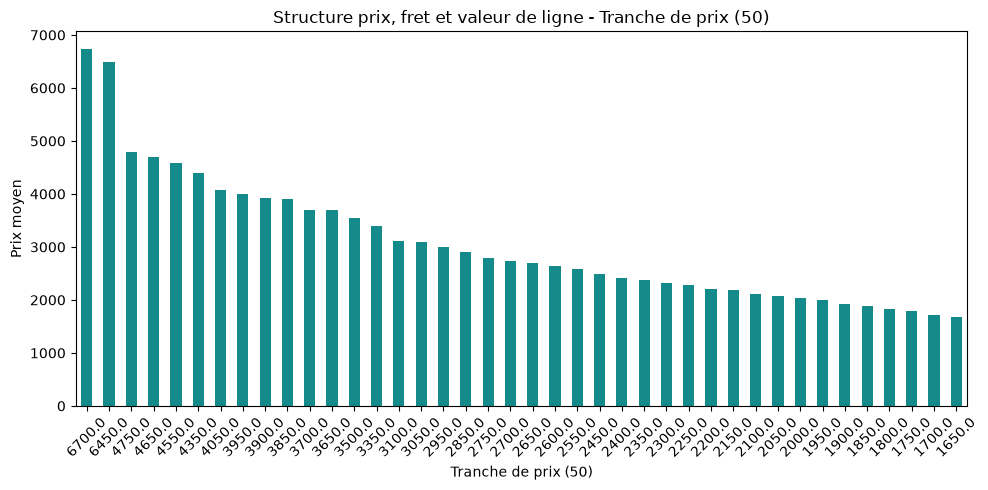

Visuel 2 - Structure prix, fret et valeur de ligne - Tranche de fret (10)


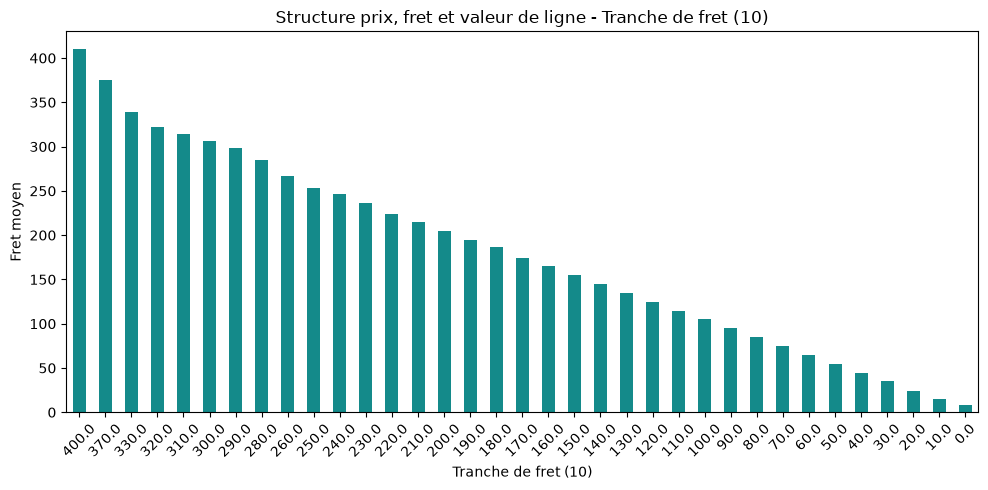

Visuel 3 - Structure prix, fret et valeur de ligne - Catégorie


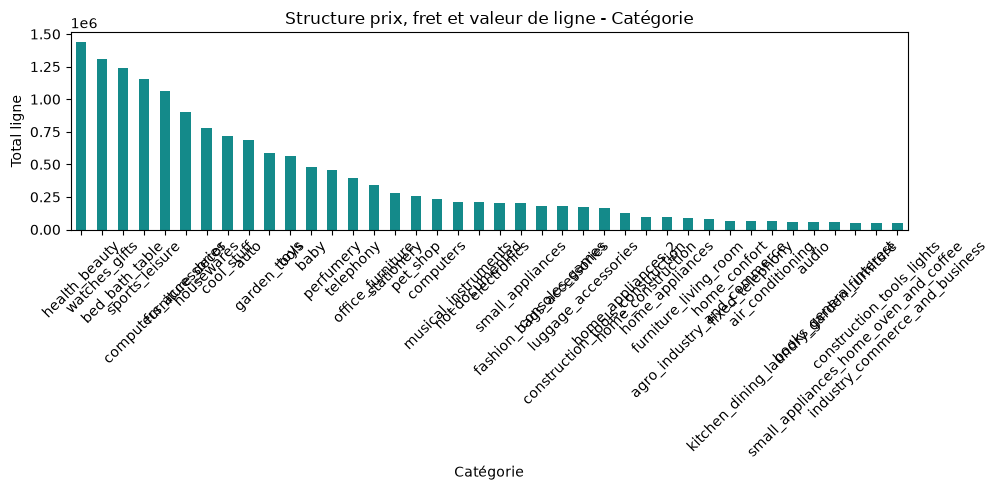

Visuel 4 - Structure prix, fret et valeur de ligne - État vendeur


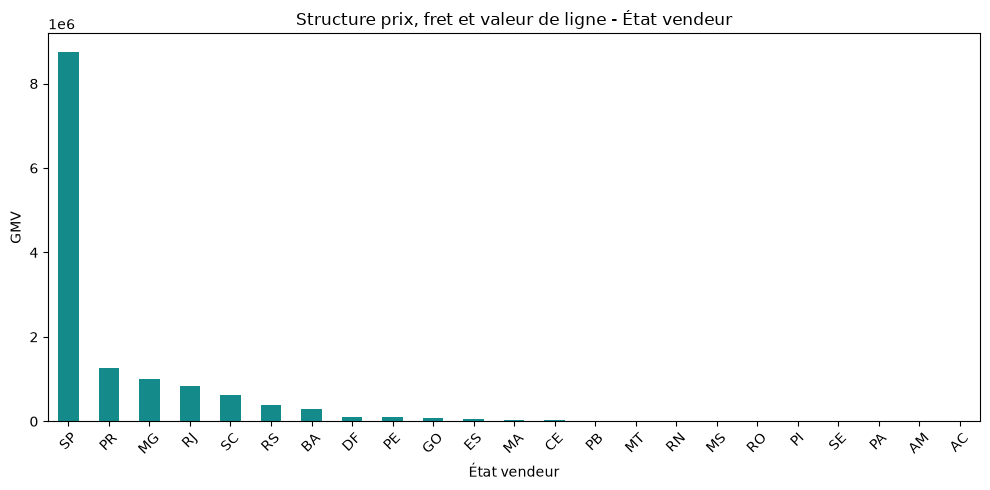

Visuel 5 - Structure prix, fret et valeur de ligne - État client


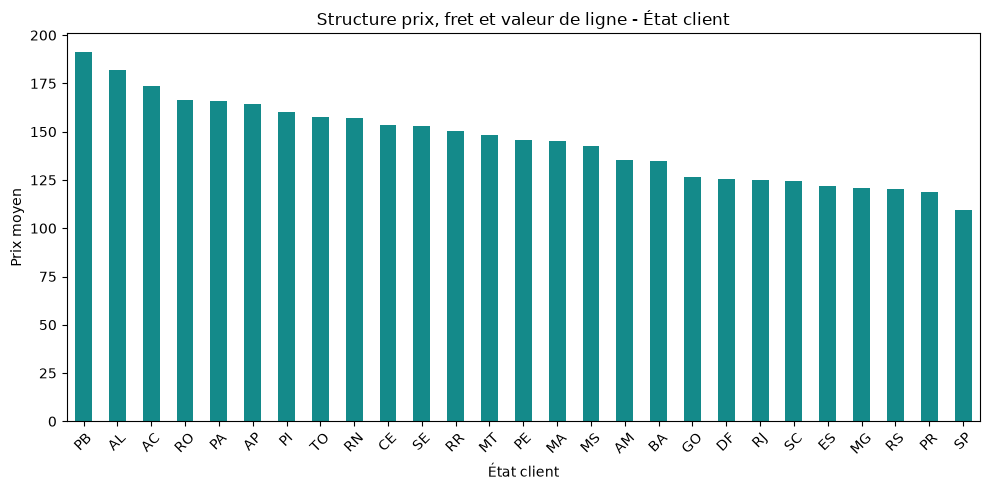

Visuel 6 - Structure prix, fret et valeur de ligne - Poids produit (kg)


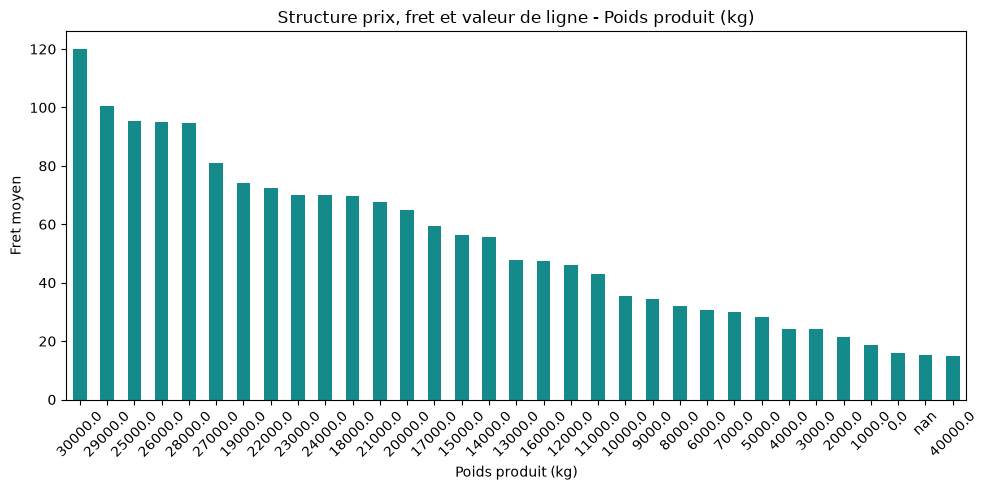

Visuel 7 - Structure prix, fret et valeur de ligne - Mois d’achat


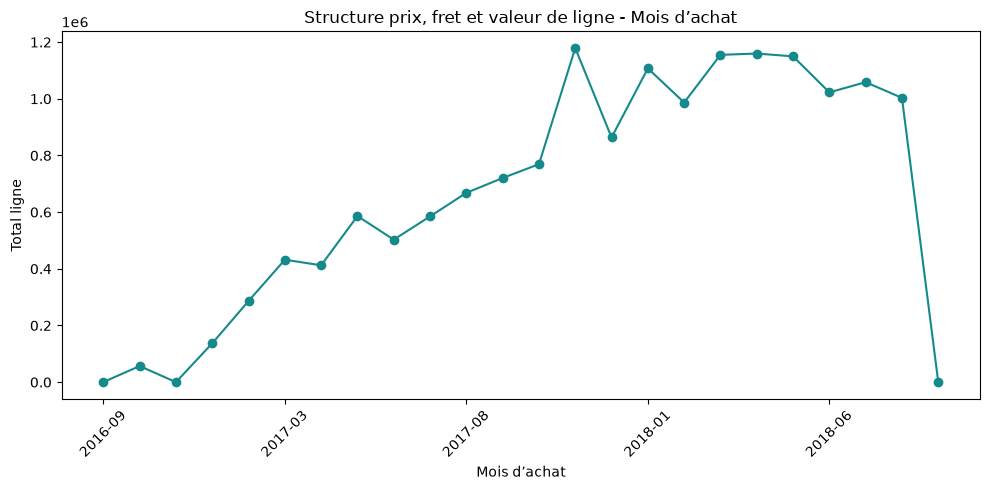

Visuel 8 - Structure prix, fret et valeur de ligne - Prix x fret


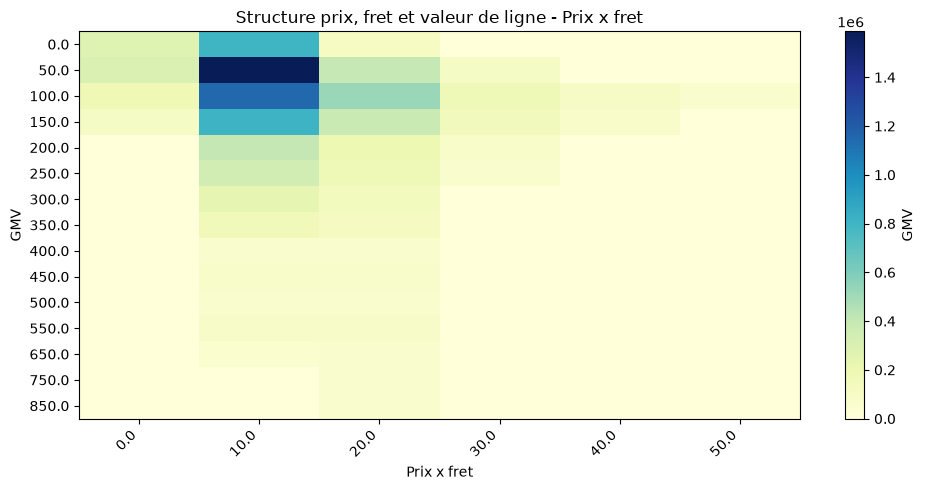

Visuel 9 - Structure prix, fret et valeur de ligne - Catégorie x état client


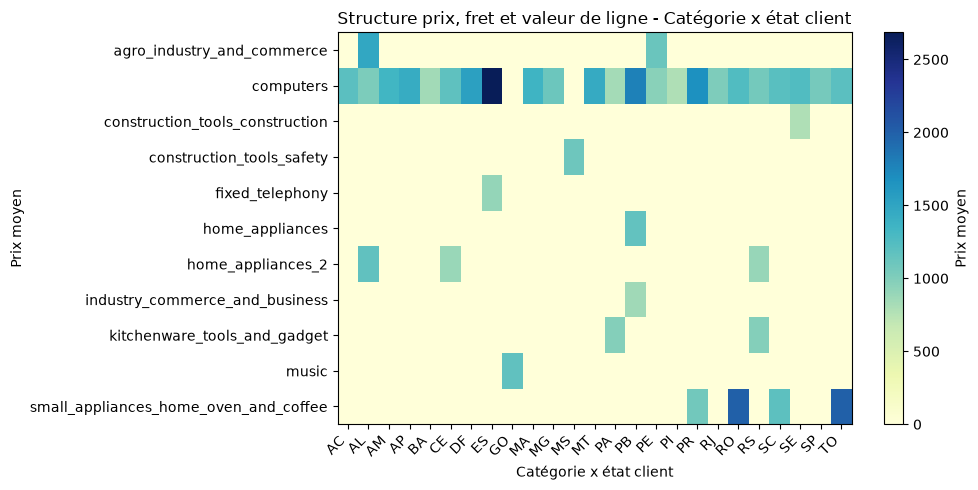

Visuel 10 - Structure prix, fret et valeur de ligne - Vendeur x catégorie


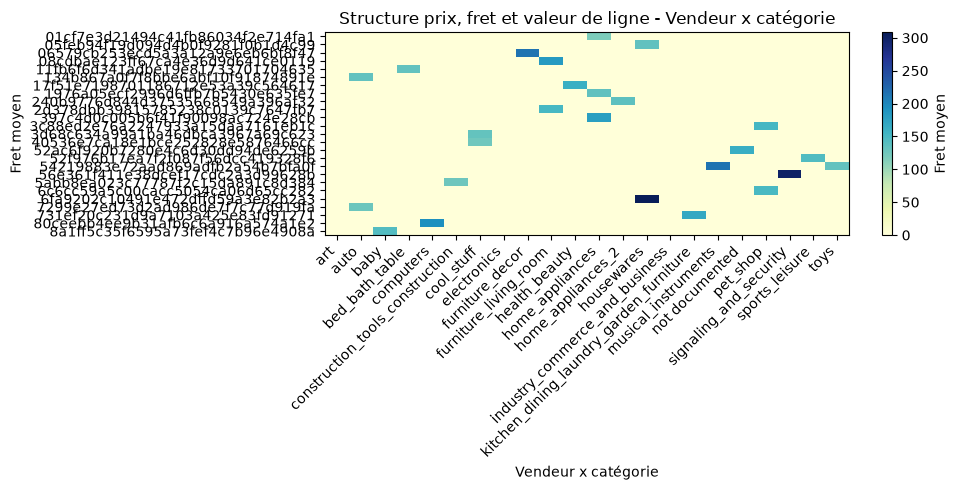

In [6]:
CHARTS=[
  {
    "n": 1,
    "title": "Structure prix, fret et valeur de ligne - Tranche de prix (50)",
    "dim": {
      "label": "Tranche de prix (50)",
      "sql": "FLOOR(\"price\" / 50) * 50",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Prix moyen",
      "sql": "AVG(\"price\")",
      "pandas": "price"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Structure prix, fret et valeur de ligne - Tranche de fret (10)",
    "dim": {
      "label": "Tranche de fret (10)",
      "sql": "FLOOR(\"freight_value\" / 10) * 10",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Fret moyen",
      "sql": "AVG(\"freight_value\")",
      "pandas": "freight_value"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Structure prix, fret et valeur de ligne - Catégorie",
    "dim": {
      "label": "Catégorie",
      "sql": "\"category_name\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Total ligne",
      "sql": "SUM(\"line_total\")",
      "pandas": "line_total"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Structure prix, fret et valeur de ligne - État vendeur",
    "dim": {
      "label": "État vendeur",
      "sql": "\"seller_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Structure prix, fret et valeur de ligne - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Prix moyen",
      "sql": "AVG(\"price\")",
      "pandas": "price"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Structure prix, fret et valeur de ligne - Poids produit (kg)",
    "dim": {
      "label": "Poids produit (kg)",
      "sql": "FLOOR(\"product_weight_g\" / 1000) * 1000",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Fret moyen",
      "sql": "AVG(\"freight_value\")",
      "pandas": "freight_value"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Structure prix, fret et valeur de ligne - Mois d’achat",
    "dim": {
      "label": "Mois d’achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\", 1, 7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Total ligne",
      "sql": "SUM(\"line_total\")",
      "pandas": "line_total"
    },
    "kind": "line"
  },
  {
    "n": 8,
    "title": "Structure prix, fret et valeur de ligne - Prix x fret",
    "dim": {
      "label": "Prix x fret",
      "sql": "FLOOR(\"price\" / 50) * 50",
      "type": "numeric",
      "series": "FLOOR(\"freight_value\" / 10) * 10"
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Structure prix, fret et valeur de ligne - Catégorie x état client",
    "dim": {
      "label": "Catégorie x état client",
      "sql": "\"category_name\"",
      "type": "categorical",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Prix moyen",
      "sql": "AVG(\"price\")",
      "pandas": "price"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Structure prix, fret et valeur de ligne - Vendeur x catégorie",
    "dim": {
      "label": "Vendeur x catégorie",
      "sql": "\"seller_id\"",
      "type": "categorical",
      "series": "\"category_name\""
    },
    "metric": {
      "label": "Fret moyen",
      "sql": "AVG(\"freight_value\")",
      "pandas": "freight_value"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 5. Géographie de la demande et du réseau vendeur

Décrire où se concentrent les lignes vendues et comment les marchés clients se relient aux implantations des vendeurs.

**Drill-down :** État > ville > code postal; client x vendeur; drill-through vers produit, catégorie et commande.

Visuel 1 - Géographie de la demande et du réseau vendeur - État client


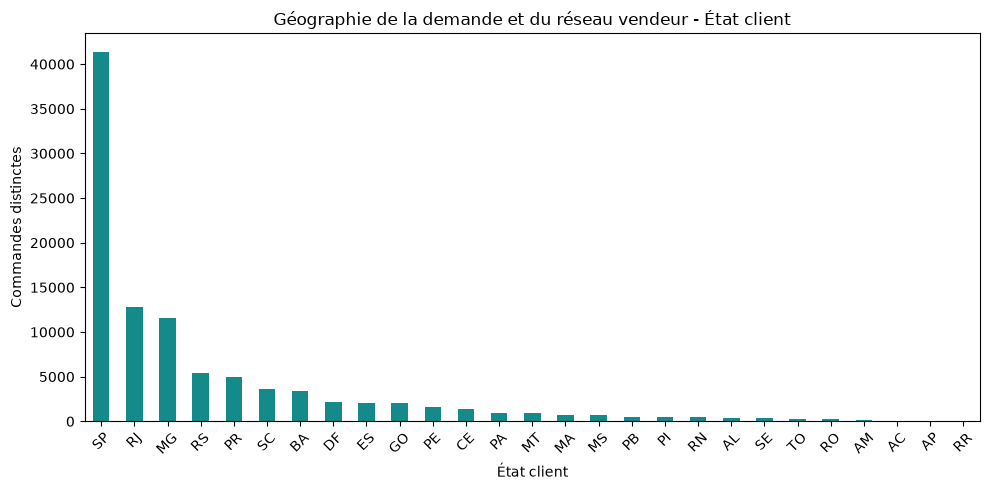

Visuel 2 - Géographie de la demande et du réseau vendeur - Ville client


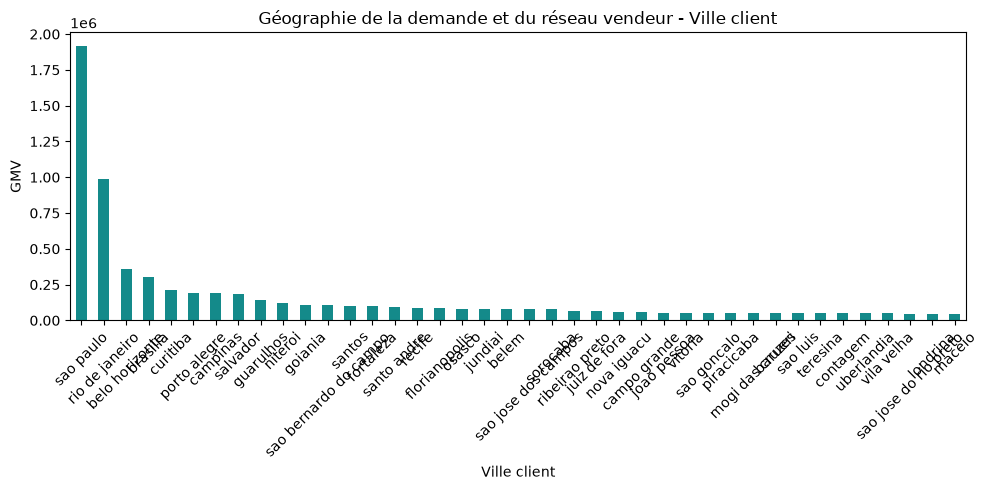

Visuel 3 - Géographie de la demande et du réseau vendeur - Code postal client


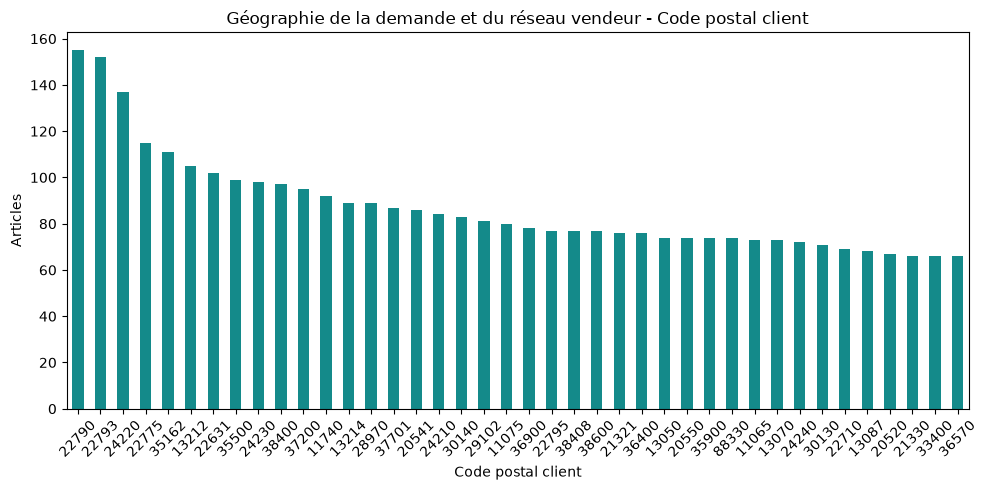

Visuel 4 - Géographie de la demande et du réseau vendeur - État vendeur


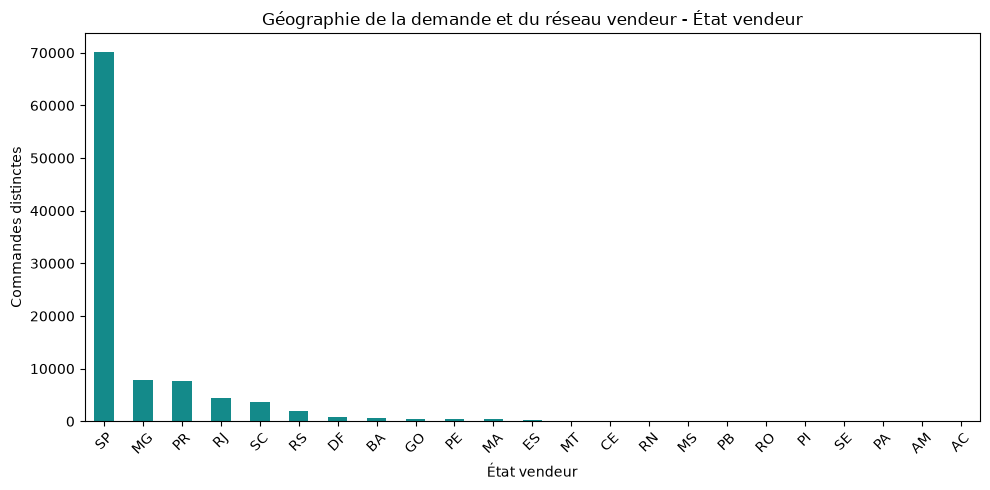

Visuel 5 - Géographie de la demande et du réseau vendeur - Ville vendeur


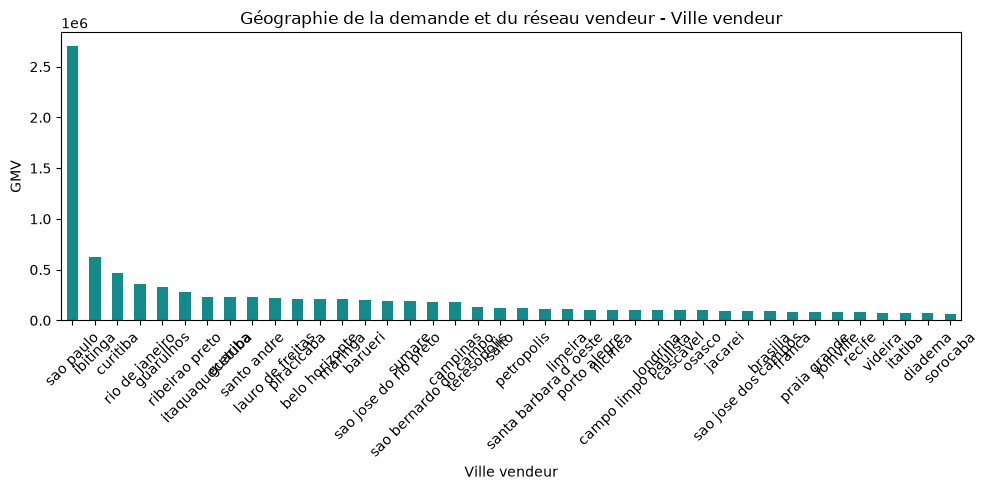

Visuel 6 - Géographie de la demande et du réseau vendeur - État client x état vendeur


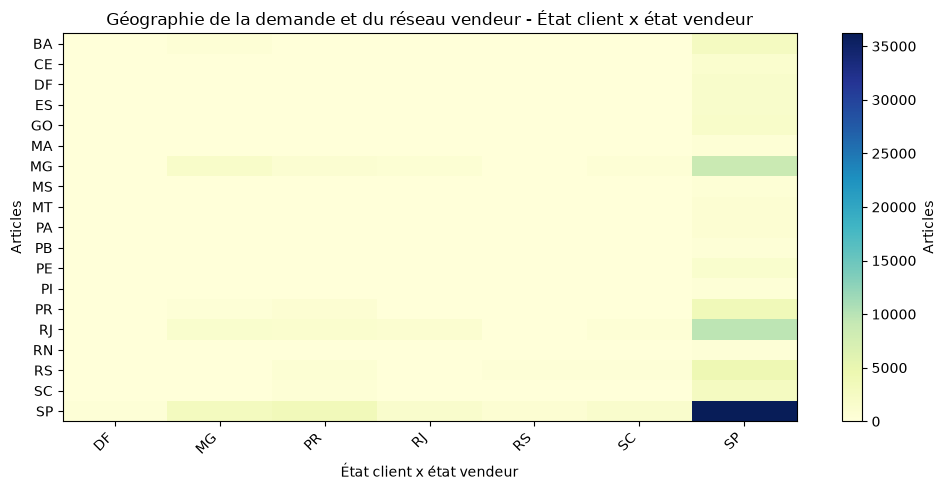

Visuel 7 - Géographie de la demande et du réseau vendeur - Catégorie x état client


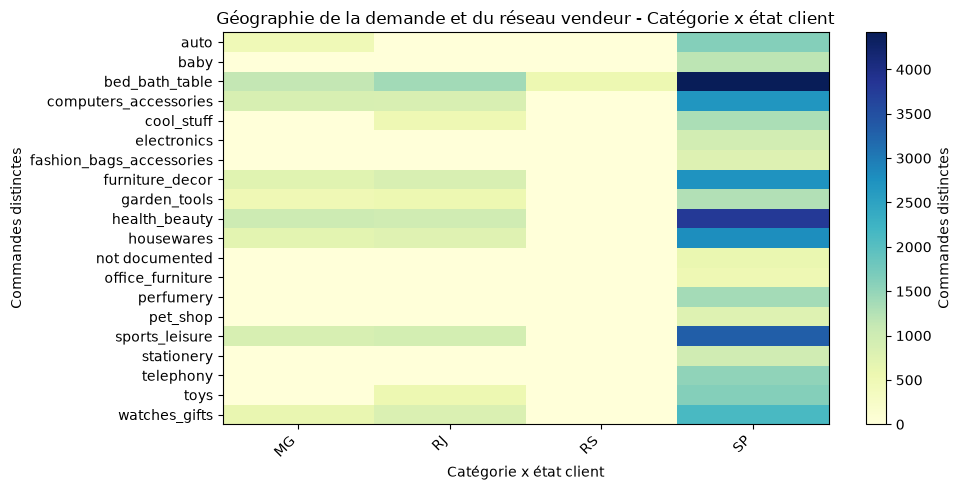

Visuel 8 - Géographie de la demande et du réseau vendeur - Mois d’achat


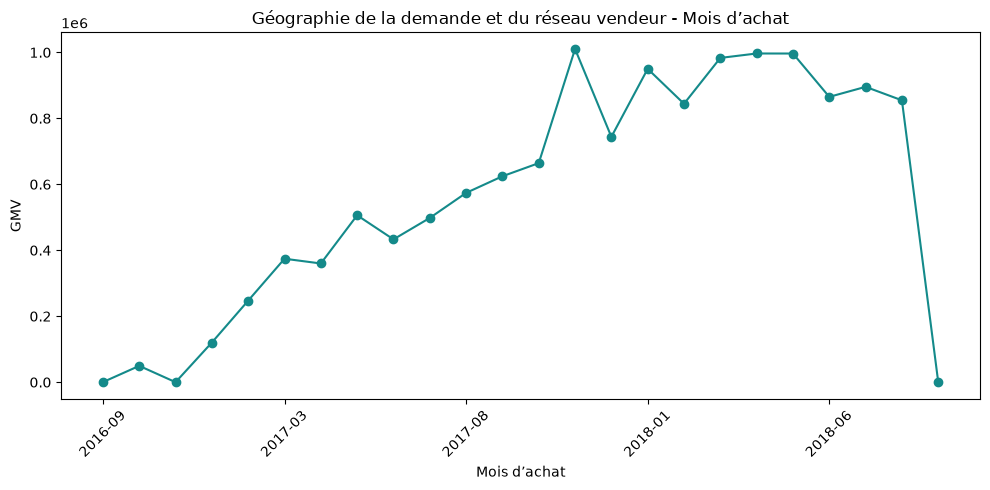

Visuel 9 - Géographie de la demande et du réseau vendeur - Latitude client


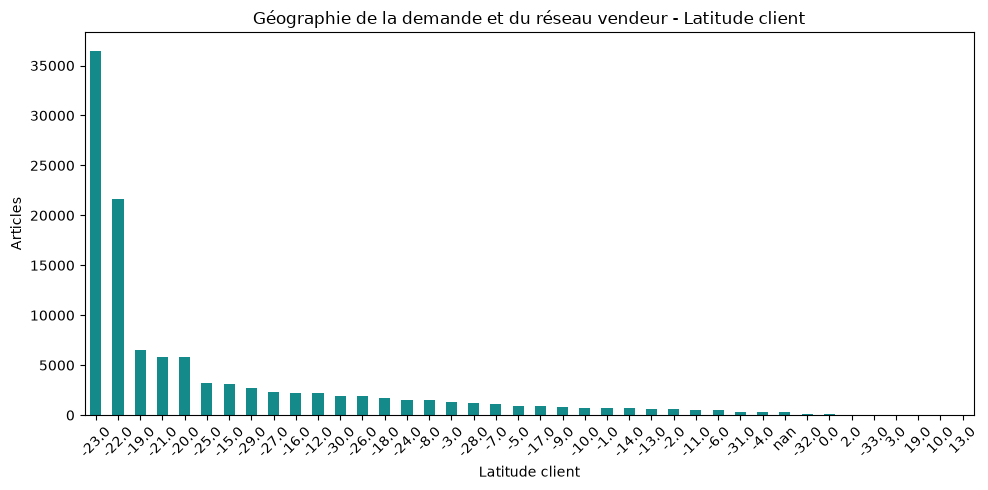

Visuel 10 - Géographie de la demande et du réseau vendeur - Longitude client


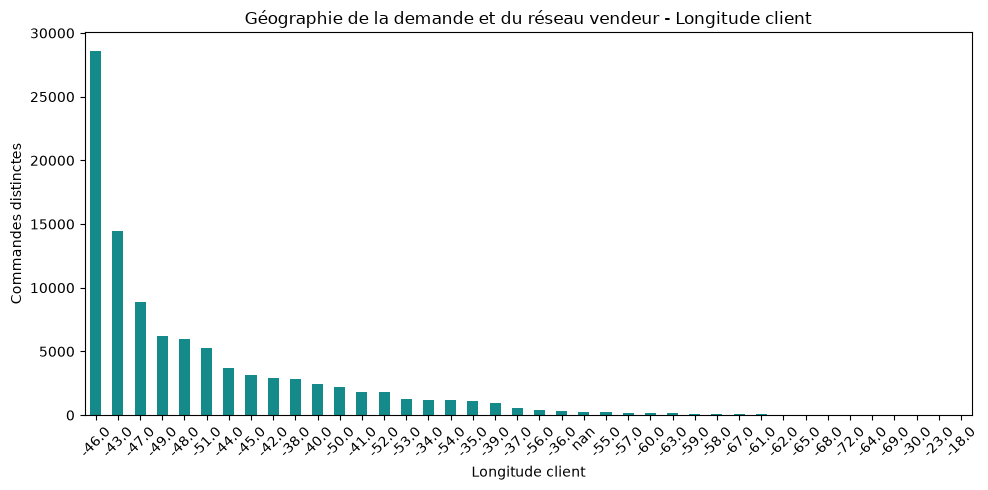

In [7]:
CHARTS=[
  {
    "n": 1,
    "title": "Géographie de la demande et du réseau vendeur - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Géographie de la demande et du réseau vendeur - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Géographie de la demande et du réseau vendeur - Code postal client",
    "dim": {
      "label": "Code postal client",
      "sql": "\"customer_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Géographie de la demande et du réseau vendeur - État vendeur",
    "dim": {
      "label": "État vendeur",
      "sql": "\"seller_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Géographie de la demande et du réseau vendeur - Ville vendeur",
    "dim": {
      "label": "Ville vendeur",
      "sql": "\"seller_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Géographie de la demande et du réseau vendeur - État client x état vendeur",
    "dim": {
      "label": "État client x état vendeur",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"seller_state\""
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 7,
    "title": "Géographie de la demande et du réseau vendeur - Catégorie x état client",
    "dim": {
      "label": "Catégorie x état client",
      "sql": "\"category_name\"",
      "type": "categorical",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "heatmap"
  },
  {
    "n": 8,
    "title": "Géographie de la demande et du réseau vendeur - Mois d’achat",
    "dim": {
      "label": "Mois d’achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\", 1, 7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "GMV",
      "sql": "SUM(\"gmv\")",
      "pandas": "gmv"
    },
    "kind": "line"
  },
  {
    "n": 9,
    "title": "Géographie de la demande et du réseau vendeur - Latitude client",
    "dim": {
      "label": "Latitude client",
      "sql": "FLOOR(\"customer_latitude\" * 10) / 10",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 10,
    "title": "Géographie de la demande et du réseau vendeur - Longitude client",
    "dim": {
      "label": "Longitude client",
      "sql": "FLOOR(\"customer_longitude\" * 10) / 10",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## Lecture des résultats\n\nComparer les valeurs aux volumes, vérifier les petits effectifs et suivre les chemins de drill-down du dossier. Les ratios et moyennes se recalculent au niveau affiché. Une association ne démontre pas une causalité.